In [2]:
import pandas as pd

ew = pd.read_csv("../data/england_wales_names.csv")
ni = pd.read_csv("../data/ni_names.csv")
sc = pd.read_csv("../data/scotland_names.csv")

datasets = {
    "England & Wales": ew,
    "Northern Ireland": ni,
    "Scotland": sc
}

results = []

for region, df in datasets.items():
    data = df[
        (df["Year"] == 2024) & df["Number"].notna()
    ]

    for sex, group in data.groupby("Sex"):
        distinct_names = group["Name"].nunique()
        total_births = group["Number"].sum()

        diversity = distinct_names / total_births * 1000

        results.append({
            "Region": region,
            "Sex": sex,
            "Distinct Names": distinct_names,
            "Total Births": total_births,
            "Names per 1000 Births": diversity
        })

diversity_df = pd.DataFrame(results)
print(diversity_df.round(2).to_string(index=False))

          Region  Sex  Distinct Names  Total Births  Names per 1000 Births
 England & Wales  Boy            6651      277788.0                  23.94
 England & Wales Girl            7647      257986.0                  29.64
Northern Ireland  Boy             504        8489.0                  59.37
Northern Ireland Girl             511        7402.0                  69.04
        Scotland  Boy             925       19949.0                  46.37
        Scotland Girl            1035       18178.0                  56.94


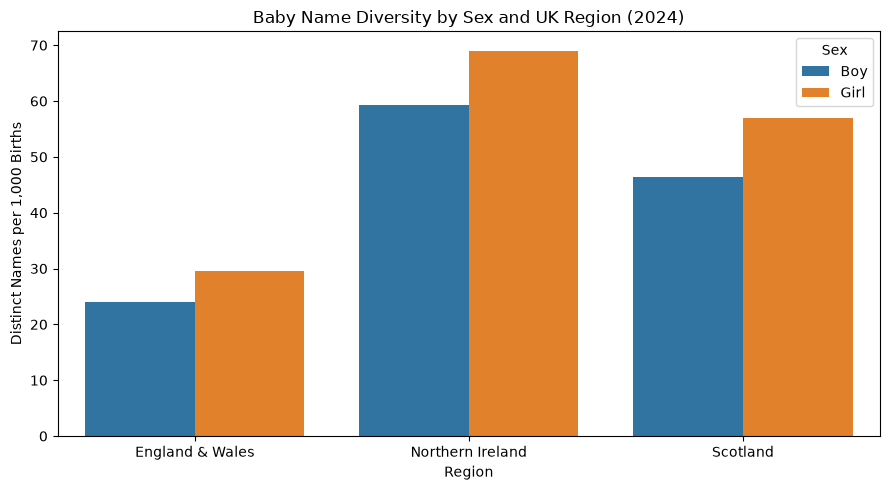

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=diversity_df,
    x="Region",
    y="Names per 1000 Births",
    hue="Sex"
)

plt.title("Baby Name Diversity by Sex and UK Region (2024)")
plt.xlabel("Region")
plt.ylabel("Distinct Names per 1,000 Births")
plt.tight_layout()

from pathlib import Path

Path("outputs").mkdir(exist_ok=True)

plt.savefig(
    "../output/name_diversity_2024.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()